# Demo 2 — QSVT trên ma trận 4×4, mạch Qiskit và đo trên Aer
**Người nói 2 · 15:30–18:30 (3 phút)**

Ý chính (RQ1): mỗi trị riêng có một không gian con 2 chiều bất biến, nên cùng một bộ pha áp được cho cả ma trận.

## Cell 1 — Ma trận và pha
$A$ đối xứng 4×4 ngẫu nhiên, chia cho $1.1\|A\|$; pha lấy từ Demo 1.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data"

import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qsvt_demo import *
import qsvt_demo

plt.rcParams.update({"font.size": 13, "figure.figsize": (8, 3.6), "axes.grid": True})
reset_rng()
print(f"Qiskit {qiskit.__version__} | numpy {np.__version__} | seed {SEED}")

A = random_hermitian(4, scale=1.1)
f1 = lambda x: 0.8 * np.cos(3 * x)
phis = np.load(DATA / "phases_cos3x_d10.npy")
print("trị riêng của A:", np.round(np.linalg.eigvalsh(A), 4))

Qiskit 2.6.2 | numpy 2.5.5 | seed 1234
trị riêng của A: [-0.7137 -0.4621 -0.1263  0.9091]


## Cell 2 — Block-encoding kiểu phản xạ
$U_A=\begin{pmatrix}A&\sqrt{I-A^2}\\\sqrt{I-A^2}&-A\end{pmatrix}$ — ancilla là qubit chỉ số cao nhất.

In [2]:
UA = block_encode(A)
e_unit = np.linalg.norm(UA @ UA.conj().T - np.eye(8))
e_block = np.linalg.norm(UA[:4, :4] - A)
print(f"||U U^† - I|| = {e_unit:.1e}   ||khối trên-trái - A|| = {e_block:.1e}")
print(verdict(e_unit < 1e-12 and e_block < 1e-12))

||U U^† - I|| = 3.8e-15   ||khối trên-trái - A|| = 0.0e+00
PASS


## Cell 3 — RQ1 bằng số: không gian con bất biến
Với $A|v\rangle=\lambda|v\rangle$, $U_A$ giữ nguyên $\mathrm{span}\{|0\rangle|v\rangle,|1\rangle|v\rangle\}$ và tác động ở đó đúng như $R(\lambda)$.

In [3]:
lam, V = np.linalg.eigh(A)
ok = True
for l, v in zip(lam, V.T):
    B = np.stack([np.kron([1, 0], v), np.kron([0, 1], v)], axis=1)   # 8x2, ancilla = qubit cao nhất
    blk = B.conj().T @ UA @ B
    leak = np.linalg.norm(UA @ B - B @ blk)
    e = np.linalg.norm(blk - R(l))
    ok &= e < 1e-12 and leak < 1e-12
    print(f"lambda = {l:+.3f}   ||blk - R(lambda)|| = {e:.1e}   rò ra ngoài = {leak:.1e}")
print(verdict(ok))

lambda = -0.714   ||blk - R(lambda)|| = 2.2e-15   rò ra ngoài = 1.4e-15
lambda = -0.462   ||blk - R(lambda)|| = 2.8e-16   rò ra ngoài = 1.1e-15
lambda = -0.126   ||blk - R(lambda)|| = 2.4e-15   rò ra ngoài = 1.8e-15
lambda = +0.909   ||blk - R(lambda)|| = 1.1e-15   rò ra ngoài = 1.1e-15
PASS


## Cell 4 — QSVT bằng ma trận: cùng 11 pha, áp lên cả $A$
So $\mathrm{Re}$ khối trên-trái với $f(A)=0.8\cos(3A)$; sai số phải cùng cỡ sai số xấp xỉ của Demo 1.

In [4]:
U = qsvt_matrix(A, phis)
err_fA = np.linalg.norm(U[:4, :4].real - f_of_A(f1, A), 2)
print(f"||Re U[:4,:4] - f(A)|| = {err_fA:.2e}", verdict(err_fA < 1e-4))

||Re U[:4,:4] - f(A)|| = 1.17e-06 PASS


## Cell 5 — Mạch Qiskit
3 qubit, ancilla là q2; mỗi pha là một $R_Z(-2\phi)$; append theo thứ tự đảo vì tích ma trận đọc từ phải.

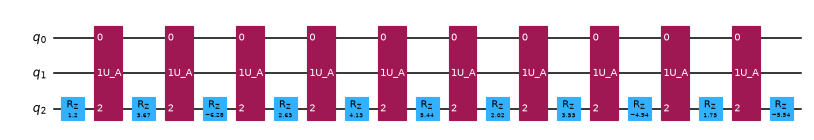

số lần gọi U_A = 10, số cổng RZ = 11
||Operator(qc) - numpy|| = 9.48e-16 PASS


In [5]:
from qiskit.quantum_info import Operator
qc = qsvt_circuit(A, phis)
display(qc.draw("mpl", fold=-1, scale=0.55))
ops = qc.count_ops()
err_circ = np.linalg.norm(Operator(qc).data - U, 2)
print(f"số lần gọi U_A = {ops.get('unitary', 0)}, số cổng RZ = {ops['rz']}")
print(f"||Operator(qc) - numpy|| = {err_circ:.2e}", verdict(err_circ < 1e-10))

## Cell 6 — E7: đo ancilla trên Aer
Chuẩn bị $|0\rangle_{anc}|{+}{+}\rangle$, chạy mạch, đo ancilla 20 000 shot. Tần suất ancilla $=0$ phải nằm trong $p\pm3\sigma$ với $p=\|P(A)\psi\|^2$; trạng thái hậu chọn phải có fidelity $>1-10^{-10}$.

In [6]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector

psi = np.ones(4) / 2                                   # |++> trên q0, q1
meas = QuantumCircuit(3, 1)
meas.initialize(psi, [0, 1])
meas.compose(qc, inplace=True)
meas.measure(2, 0)                                     # ancilla = q2
sim, N = AerSimulator(seed_simulator=SEED), 20000
counts = sim.run(transpile(meas, sim), shots=N).result().get_counts()
freq = counts.get("0", 0) / N

PA_psi = U[:4, :4] @ psi                               # khối trên-trái (phức) tác động lên psi
p = np.linalg.norm(PA_psi) ** 2
sig = np.sqrt(p * (1 - p) / N)
ok_freq = abs(freq - p) <= 3 * sig
print(f"p lý thuyết = {p:.4f}   tần suất đo = {freq:.4f}   3σ = {3 * sig:.4f}", verdict(ok_freq))

sv = Statevector(np.kron([1, 0], psi)).evolve(qc).data[:4]
fid = abs(np.vdot(sv / np.linalg.norm(sv), PA_psi / np.linalg.norm(PA_psi))) ** 2
print(f"fidelity trạng thái hậu chọn = {fid:.12f}", verdict(fid > 1 - 1e-10))

p lý thuyết = 0.5217   tần suất đo = 0.5223   3σ = 0.0106 PASS
fidelity trạng thái hậu chọn = 1.000000000000 PASS
